In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.pickle_functions import pickle_file_exists, load_from_pickle
from src.label_processing import update_folds_for_training_and_evaluation

In [2]:
pickle_name_fold = "cmu_mosei"
label_type = "all"
predict_neutral_class = False
threshold_emo_present = [0]
ext_name = ""

### List of scores

In [3]:
train_list = load_from_pickle(pickle_name_fold + "_train", "raw_folds", "cmu_mosei")
y_train = train_list[1]
y_train_array = np.reshape(np.array(y_train), (-1,6))
df = pd.DataFrame(y_train_array, columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])

In [4]:
def compute_unique(label, to_return):
    all_sc = list(df[label].unique())
    all_sc.sort()
    print(all_sc)
    
    if to_return:
        return all_sc

In [5]:
compute_unique('happiness', False)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 0.8333333, 1.0, 1.3333334, 1.6666666, 2.0, 2.1666667, 2.3333333, 2.6666667, 3.0]


In [6]:
compute_unique('sadness', False)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 0.8333333, 1.0, 1.1666666, 1.3333334, 1.5, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]


In [7]:
compute_unique('anger', False)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 1.0, 1.3333334, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]


In [8]:
compute_unique('surprise', False)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 1.0, 1.3333334, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]


In [9]:
compute_unique('disgust', False)

[0.0, 0.33333334, 0.5, 0.6666667, 1.0, 1.3333334, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]


In [10]:
compute_unique('fear', False)

[0.0, 0.16666667, 0.33333334, 0.6666667, 1.0, 1.3333334, 1.6666666]


In [11]:
all_scores = compute_unique('sadness', True)

[0.0, 0.16666667, 0.33333334, 0.5, 0.6666667, 0.8333333, 1.0, 1.1666666, 1.3333334, 1.5, 1.6666666, 2.0, 2.3333333, 2.6666667, 3.0]


### Load training, validation and test data

In [12]:
train_list = load_from_pickle(pickle_name_fold + "_train", "raw_folds", "cmu_mosei")
valid_list = load_from_pickle(pickle_name_fold + "_valid", "raw_folds", "cmu_mosei")
test_list = load_from_pickle(pickle_name_fold + "_test",  "raw_folds", "cmu_mosei")

The following updates the training, validation and test folds to the suitable label type.

In [13]:
train_list, valid_list, test_list = update_folds_for_training_and_evaluation(train_list, valid_list, test_list, 
                                                                             label_type, all_scores, 
                                                                             predict_neutral_class, 
                                                                             threshold_emo_present, ext_name)

In [14]:
y_train = train_list[1]
y_train_array = np.reshape(np.array(y_train), (-1,6))
y_train_array.shape

(16315, 6)

In [15]:
y_valid = valid_list[1]
y_valid_array = np.reshape(np.array(y_valid), (-1,6))
y_valid_array.shape

(1871, 6)

In [16]:
y_test = test_list[1]
y_test_array = np.reshape(np.array(y_test), (-1,6))
y_test_array.shape

(4654, 6)

### Training data statistics

In [17]:
df = pd.DataFrame(y_train_array, columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
df

,happiness,sadness,anger,surprise,disgust,fear
0,0.666667,0.666667,0.0,0.0,0.0,0.666667
1,0.000000,0.000000,0.0,0.0,0.0,0.000000
2,0.666667,0.666667,0.0,0.0,0.0,0.333333
3,0.333333,0.333333,0.0,0.0,0.0,0.000000
4,0.666667,0.000000,0.0,0.0,0.0,0.000000
...,...,...,...,...,...,...
16310,0.000000,0.000000,0.0,0.0,0.0,0.000000
16311,0.000000,0.000000,0.0,0.0,0.0,0.000000
16312,1.000000,0.000000,0.0,0.0,0.0,0.000000
16313,0.333333,0.000000,0.0,0.0,0.0,0.000000


In [18]:
df.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,16315.000000,16315.000000,16315.000000,16315.000000,16315.000000,16315.000000
mean,0.487206,0.160976,0.157768,0.048840,0.124335,0.040494
std,0.640092,0.331289,0.367441,0.171966,0.327232,0.151933
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.666667,0.333333,0.000000,0.000000,0.000000,0.000000
max,3.000000,3.000000,3.000000,3.000000,3.000000,1.666667


<AxesSubplot:title={'center':'Number of training samples per class and per presence score'}, ylabel='Frequency'>

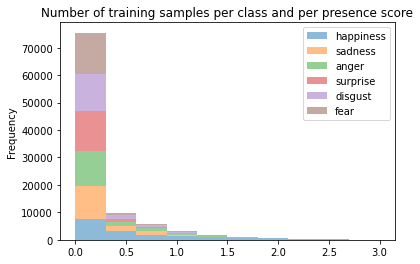

In [19]:
df.plot.hist(alpha=0.5, stacked=True,
            title="Number of training samples per class and per presence score")

#### Get the number of samples for each pair (class, presence score)

In [20]:
count_train = []
for sc in all_scores:
    l = np.sum(y_train_array==sc, axis=0)
    count_train.append(l)
count_train_arr = np.array(count_train)
count_train_arr.shape

df_scores_train = pd.DataFrame(count_train_arr, 
                               columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'],
                               index=all_scores)
df_scores_train

,happiness,sadness,anger,surprise,disgust,fear
0.000000,7588,12048,12792,14673,13361,14985
0.166667,18,7,1,2,0,8
0.333333,3055,2023,1398,1133,1343,816
0.500000,7,2,1,1,1,0
0.666667,1825,1416,935,355,824,372
0.833333,2,1,0,0,0,0
1.000000,1252,506,736,100,393,121
1.166667,0,1,0,0,0,0
1.333333,949,176,212,26,195,10
1.500000,0,1,0,0,0,0


<AxesSubplot:title={'center':'Number of training samples per class and per presence score'}>

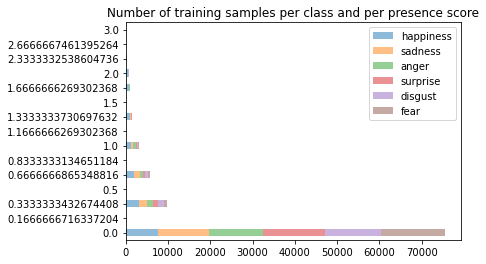

In [21]:
df_scores_train.plot.barh(alpha=0.5, stacked=True,
                          title="Number of training samples per class and per presence score")

<AxesSubplot:title={'center':'Number of training samples per class and per presence score'}, xlabel='Presence score of the emotion'>

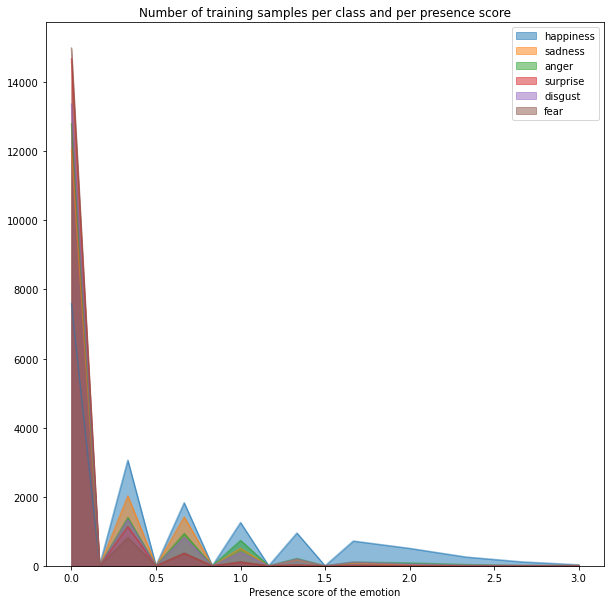

In [22]:
df_scores_train.index.name = 'Presence score of the emotion'
df_scores_train.plot.area(stacked=False, figsize=(10,10), 
                          title="Number of training samples per class and per presence score")

### Validation data statistics

In [23]:
df = pd.DataFrame(y_valid_array, columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
df

,happiness,sadness,anger,surprise,disgust,fear
0,0.666667,0.000000,0.0,0.0,0.000000,0.000000
1,0.000000,0.000000,0.0,0.0,0.000000,0.000000
2,0.333333,0.333333,0.0,0.0,0.000000,0.000000
3,0.333333,0.000000,0.0,0.0,0.000000,0.000000
4,0.000000,0.333333,0.0,0.0,0.000000,0.000000
...,...,...,...,...,...,...
1866,0.000000,0.000000,0.0,0.0,0.000000,0.000000
1867,0.333333,0.000000,0.0,0.0,0.000000,0.000000
1868,0.333333,0.000000,0.0,0.0,0.000000,0.000000
1869,0.333333,0.000000,0.0,0.0,0.000000,0.333333


In [24]:
df.describe()

,happiness,sadness,anger,surprise,disgust,fear
count,1871.000000,1871.000000,1871.000000,1871.000000,1871.000000,1871.000000
mean,0.438803,0.167379,0.122038,0.050330,0.089791,0.044094
std,0.578875,0.326579,0.303887,0.165431,0.263015,0.153105
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.666667,0.333333,0.000000,0.000000,0.000000,0.000000
max,3.000000,3.000000,2.333333,1.666667,2.666667,1.000000


<AxesSubplot:title={'center':'Number of validation samples per class and per presence score'}, ylabel='Frequency'>

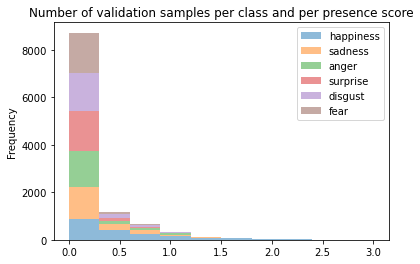

In [25]:
df.name = 'Presence score of the emotion'
df.plot.hist(alpha=0.5, stacked=True,
            title="Number of validation samples per class and per presence score")

#### Get the number of samples for each pair (class, presence score)

In [26]:
count_valid = []
for sc in all_scores:
    l = np.sum(y_valid_array==sc, axis=0)
    count_valid.append(l)
count_valid_arr = np.array(count_valid)
count_valid_arr.shape

df_scores_valid = pd.DataFrame(count_valid_arr, 
                               columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'],
                               index=all_scores)
df_scores_valid

,happiness,sadness,anger,surprise,disgust,fear
0.000000,866,1351,1533,1668,1590,1695
0.166667,4,3,0,3,0,4
0.333333,402,243,133,139,152,115
0.500000,1,0,0,1,0,1
0.666667,220,181,107,47,76,39
0.833333,4,0,0,0,0,0
1.000000,141,62,72,7,34,17
1.166667,3,0,0,1,0,0
1.333333,84,19,15,3,8,0
1.500000,0,0,0,0,0,0


<AxesSubplot:title={'center':'Number of validation samples per class and per presence score'}>

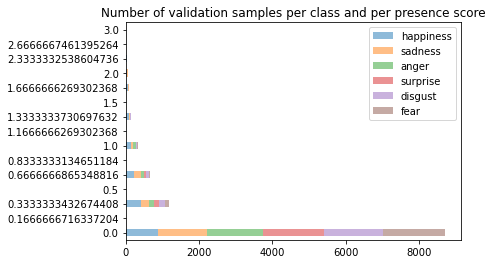

In [27]:
df_scores_valid.plot.barh(alpha=0.5, stacked=True,
                          title="Number of validation samples per class and per presence score")

<AxesSubplot:title={'center':'Number of validation samples per class and per presence score'}, xlabel='Presence score of the emotion'>

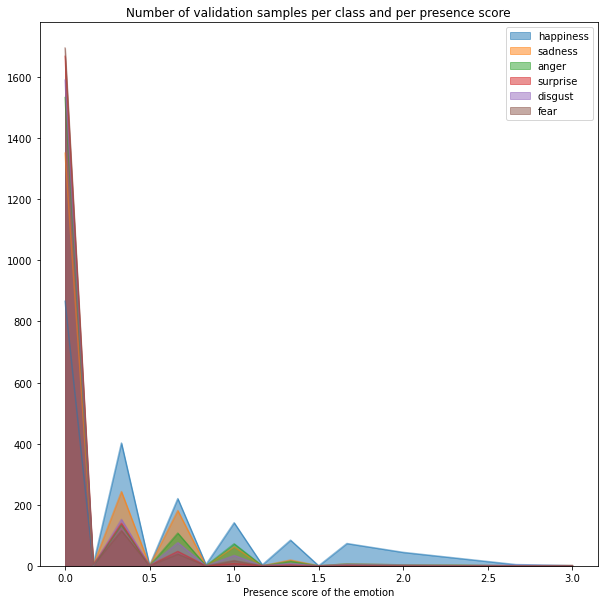

In [28]:
df_scores_valid.index.name = 'Presence score of the emotion'
df_scores_valid.plot.area(stacked=False, figsize=(10,10), 
                         title="Number of validation samples per class and per presence score")

### Test data statistics

In [29]:
df = pd.DataFrame(y_test_array, columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'])
df

,happiness,sadness,anger,surprise,disgust,fear
0,0.000000,0.333333,0.333333,0.0,0.0,0.000000
1,0.000000,0.333333,0.000000,0.0,0.0,0.000000
2,0.000000,0.333333,0.000000,0.0,0.0,0.000000
3,1.333333,0.000000,0.000000,0.0,0.0,0.000000
4,1.000000,0.000000,0.000000,0.0,0.0,0.000000
...,...,...,...,...,...,...
4649,0.666667,0.000000,0.000000,0.0,0.0,0.333333
4650,0.000000,0.000000,0.000000,0.0,0.0,0.000000
4651,0.333333,0.000000,0.000000,0.0,0.0,0.000000
4652,2.333333,0.000000,0.000000,0.0,0.0,0.000000


In [30]:
df.describe(include='all')

,happiness,sadness,anger,surprise,disgust,fear
count,4654.000000,4654.000000,4654.000000,4654.000000,4654.000000,4654.000000
mean,0.468772,0.144428,0.163372,0.044120,0.117354,0.042687
std,0.606240,0.302392,0.360659,0.155794,0.317076,0.156503
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.666667,0.000000,0.000000,0.000000,0.000000,0.000000
max,3.000000,2.333333,3.000000,2.333333,3.000000,1.333333


<AxesSubplot:title={'center':'Number of test samples per class and per presence score'}, ylabel='Frequency'>

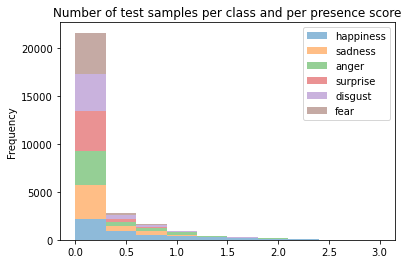

In [31]:
df.name = 'Presence score of the emotion'
df.plot.hist(alpha=0.5, stacked=True,
            title="Number of test samples per class and per presence score")

#### Get the number of samples for each pair (class, presence score)

In [32]:
count_test = []
for sc in all_scores:
    l = np.sum(y_test_array==sc, axis=0)
    count_test.append(l)
count_test_arr = np.array(count_test)
count_test_arr.shape

df_scores_test = pd.DataFrame(count_test_arr, 
                               columns=['happiness', 'sadness', 'anger', 'surprise', 'disgust', 'fear'],
                               index=all_scores)
df_scores_test

,happiness,sadness,anger,surprise,disgust,fear
0.000000,2156,3526,3584,4213,3849,4269
0.166667,1,2,0,0,0,0
0.333333,890,548,411,315,381,213
0.500000,1,1,0,0,1,0
0.666667,549,356,319,88,196,136
0.833333,0,0,0,0,0,0
1.000000,379,164,226,30,130,33
1.166667,0,0,0,0,0,0
1.333333,282,36,63,7,49,3
1.500000,0,0,0,0,0,0


<AxesSubplot:title={'center':'Number of test samples per class and per presence score'}>

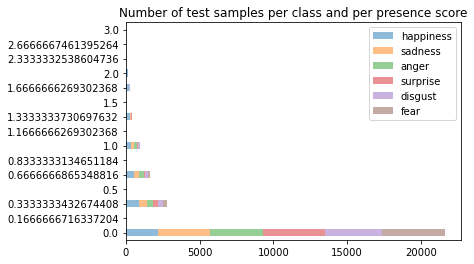

In [33]:
df_scores_test.plot.barh(alpha=0.5, stacked=True, 
                         title="Number of test samples per class and per presence score")

<AxesSubplot:title={'center':'Number of test samples per class and per presence score'}, xlabel='Presence score of the emotion'>

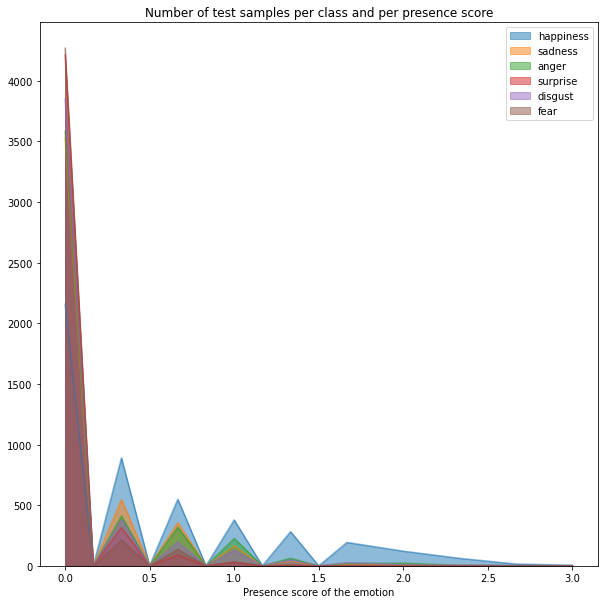

In [34]:
df_scores_test.index.name = 'Presence score of the emotion'
df_scores_test.plot.area(stacked=False, figsize=(10,10), 
                         title="Number of test samples per class and per presence score")